<a href="https://colab.research.google.com/github/jbs112233/jordan_INFO4670_Fall2026/blob/main/Logistic_Regression_Car_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 11: Assignment 4 - Logistic Regression Assignment (Age & Salary → Purchased)
**Coures:** INFO 4670 Fengjiao Tu  
**Goal:** Train and evaluate a Logistic Regression model to predict whether a customer purchases a car using `Age` and `Salary`.

---

## I. Assignment Objective
By completing this assignment, you will:
- Understand the concept and intuition of logistic regression.
- Load and preprocess data using `pandas`.
- Train and evaluate a logistic regression model with `scikit-learn`.
- Visualize classification results.
- Analyze model performance and reflect on possible improvements.


## II. Dataset Description
Expected CSV file name: **`car_purchase_data.csv`**

| Column | Description | Example |
|--------|-------------|---------|
| `Age` | Age of the customer | 35 |
| `Salary` | Annual or monthly income | 60000 |
| `Purchased` | Whether the customer purchased a car (1 = Yes, 0 = No) | 1 |


---
# Grading Rubric (Total = 100 points)

| Section | Description | Points | Details |
|--------|-------------|--------|---------|
| **Objective Understanding** | Explain purpose and logic of logistic regression | 10 | Goal & rationale (5); why LR for this task (5) |
| **Data Preparation** | Data loading, splitting, scaling | 20 | Import & preview (5); X/y split (5); train/test (5); scaling (5) |
| ** Model Training & Evaluation** | Fit, predict, metrics, visualization | 40 | Trained correctly (10); metrics shown (10); **accuracy ≥ 87.5% (10)**; visualization (10) |
| ** Analysis & Reflection** | Interpretation and critical thinking | 30 | Probability→class explanation (10); result discussion (10); improvements (10) |


**Accuracy Requirement:**
- Full credit (10 pts) if **accuracy ≥ 87.5%**
- Partial (7–9 pts) if **80% ≤ accuracy < 87.5%**
- Minimal (≤5 pts) if **accuracy < 80%**
- 0 pts if the model fails to run


## III. Steps to Complete
Follow the cells below in order. According to the hands-on task, please complete the code.

### Step 1: Import libraries and load data

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# Corrected file path
df = pd.read_csv("car_purchase_data (1).csv")

print(df.head())

print("\nDataset shape:", df.shape)
print("\nColumn names:", df.columns.tolist())
print("\nMissing values:\n", df.isnull().sum())

    User ID  Gender  Age  Salary  Purchased
0  15624510    Male   19   19000          0
1  15810944    Male   35   20000          0
2  15668575  Female   26   43000          0
3  15603246  Female   27   57000          0
4  15804002    Male   19   76000          0

Dataset shape: (400, 5)

Column names: ['User ID', 'Gender', 'Age', 'Salary', 'Purchased']

Missing values:
 User ID      0
Gender       0
Age          0
Salary       0
Purchased    0
dtype: int64


### Step 2: Split features and target

In [7]:
# Define features (X) and target variable (y)
X = df[['Age', 'Salary']]
y = df['Purchased']

print("Features (X) shape:", X.shape)
print("Target (y) shape:", y.shape)

Features (X) shape: (400, 2)
Target (y) shape: (400,)


### Step 3: Train/Test Split

In [8]:
# Perform Train/Test Split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (320, 2)
X_test shape: (80, 2)
y_train shape: (320,)
y_test shape: (80,)


### Step 4: Feature Scaling

In [9]:
# Initialize StandardScaler
scaler = StandardScaler()

# Fit on training data and transform both training and testing sets
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("First 5 rows of scaled training features:\n", X_train_scaled[:5])

First 5 rows of scaled training features:
 [[-1.06675246 -0.38634438]
 [ 0.79753468 -1.22993871]
 [ 0.11069205  1.853544  ]
 [ 0.60129393 -0.90995465]
 [ 1.87685881 -1.28811763]]


### Step 5: Train Logistic Regression Model

In [10]:
# Initialize the Logistic Regression model
model = LogisticRegression(random_state=42)

# Train the model
model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


### Step 6: Predict and Evaluate

In [11]:
# Make predictions on the scaled testing set
y_pred = model.predict(X_test_scaled)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
class_report = classification_report(y_test, y_pred)

# Display the results
print(f"Accuracy Score: {accuracy * 100:.2f}%")
print("\nConfusion Matrix:\n", conf_matrix)
print("\nClassification Report:\n", class_report)

Accuracy Score: 86.25%

Confusion Matrix:
 [[50  2]
 [ 9 19]]

Classification Report:
               precision    recall  f1-score   support

           0       0.85      0.96      0.90        52
           1       0.90      0.68      0.78        28

    accuracy                           0.86        80
   macro avg       0.88      0.82      0.84        80
weighted avg       0.87      0.86      0.86        80



### Step 7: Visualization of Decision Regions

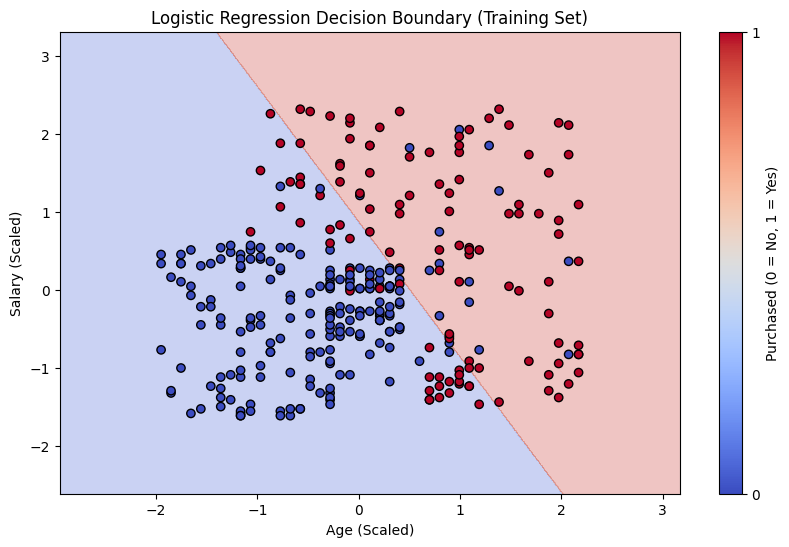

In [12]:
# Create a mesh grid of points to plot the decision boundary
x_min, x_max = X_train_scaled[:, 0].min() - 1, X_train_scaled[:, 0].max() + 1
y_min, y_max = X_train_scaled[:, 1].min() - 1, X_train_scaled[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.01), np.arange(y_min, y_max, 0.01))

# Predict the class for each point in the mesh grid
Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Set up the plot
plt.figure(figsize=(10, 6))
plt.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.coolwarm)

# Plot the training points
scatter = plt.scatter(
    X_train_scaled[:, 0],
    X_train_scaled[:, 1],
    c=y_train,
    cmap=plt.cm.coolwarm,
    edgecolor='k',
    label='Train Set'
)

plt.xlabel('Age (Scaled)')
plt.ylabel('Salary (Scaled)')
plt.title('Logistic Regression Decision Boundary (Training Set)')
plt.colorbar(scatter, ticks=[0, 1], label='Purchased (0 = No, 1 = Yes)')
plt.show()

## IV. Reflection Questions
1. Logistic regression outputs probabilities — why can it still be used for classification?
2. Based on your model, which customers are more likely to purchase a car?
3. What factors might cause low accuracy in this task?
4. Propose additional features or preprocessing steps that could improve accuracy.


### **Answers to Reflection Questions**

#### **1. Logistic regression outputs probabilities — why can it still be used for classification?**

Using the logistic sigmoid function, logistic regression determines the likelihood that an observation is a member of a specific class. The expected probability for binary categorization ranges from 0 to 1. This probability is transformed into a class label by a threshold, typically 0.5. The model predicts class 1 bought if the likelihood is at least 0.5; else, it predicts class 0 not purchased. As a result, logistic regression can utilize probabilities to decide how to classify data.

#### **2. Based on your model, which customers are more likely to purchase a car?**

According to the model trained with age and salary, clients who are older and earn more money are more likely to buy a car. The training data is used to teach the model how these attributes relate to purchase behavior. However, these associations are predictions based on this dataset and do not guaranty that a specific client will buy a car.

#### **3. What factors might cause low accuracy in this task?**

A limited dataset, erroneous or noisy data, or consumer purchasing patterns that cannot be fully explained by age and income alone can all contribute to low accuracy. Purchase decisions may also be influenced by other variables, including the automobile's cost, credit score, current car ownership, work situation, and personal preferences. Performance may also be impacted by class imbalance, an inappropriate decision threshold, or a model that fails to account for intricate linkages.

#### **4. Propose additional features or preprocessing steps that could improve accuracy.**

I could improve the model by include important features such as credit score, employment status, monthly costs, automobile pricing, and past vehicle ownership, assuming that these data are available and appropriate for usage. I could also look for outliers, assess data quality, and compare different feature-scaling and preprocessing methods. Performance could be improved by testing various classification algorithms, such as decision trees or random forests, and tuning model parameters using cross-validation. Finally, I would compare the model's precision, recall, F1-score, and accuracy to check that it performs well in both classes.